# 02 – Envelope: minimal average enclosing volume (proton)

## 1. Introduction

This model does not describe the average density but an **envelope**: the smallest body of revolution that contains most of the showers.
Think of it as the **smallest bag** that holds 95% of the energy for 98% of proton showers of a given energy.
Going to 100% is not worthwhile: a few strongly fluctuating showers would make the bag needlessly large, which would later hurt
the separation of nearby showers.

Envelope shape:

$$r(z') = A\, u^{a} e^{-b u}, \qquad u = z' - z_0, \qquad V = \pi A^2\, \frac{\Gamma(2a+1)}{(2b)^{2a+1}}$$

- $a$, $b$: the envelope shape; the thickest point is at depth $z' = z_0 + a/b$ (in the table `z_env` $= a/b$ measured from $z_0$, `z_thick` $= z_0 + a/b$).
- $A$: the size.
- $z_0$: the starting point (the origin is the first layer; due to oblique incidence negative $z'$ also occurs).
- $V$: the envelope **volume**, i.e. the volume of the body of revolution obtained by rotating the curve $r(z')$ around the $z'$ axis.
  At each depth $z'$ the envelope cross-section is a circle of area $\pi r(z')^2$; these are summed along the depth:

$$V = \int_{z_0}^{\infty} \pi\, r(z')^2 \, dz' = \pi A^2 \int_0^{\infty} u^{2a} e^{-2bu}\, du = \pi A^2\, \frac{\Gamma(2a+1)}{(2b)^{2a+1}}$$

  The last step is the definition of the Gamma function ($\int_0^\infty u^{k} e^{-cu} du = \Gamma(k+1)/c^{k+1}$). $V$ comes out in mm³; in plots
  and tables it is shown in litres ($1\ \mathrm{L} = 10^6\ \mathrm{mm}^3$, column `V_L`).
  Reason for the conversion: $1\ \mathrm{L} = 1\ \mathrm{dm}^3 = (100\ \mathrm{mm})^3 = 10^6\ \mathrm{mm}^3$; in the code `V_L = exp(log_volume) / 1e6`.
  This is **for display only**: in mm³ the volumes are of order $10^7$ (e.g. 45 L = 45 000 000 mm³), which is hard to read in tables and
  on plot axes, while litres give manageable numbers. **It does not affect the fit:** the optimisation
  minimises $\ln V$ in mm³, and a constant factor inside the logarithm is just an added constant, so the location of the minimum is the same.

  **What is $V$ for?** It is the **objective function** of the fit: among envelopes satisfying the condition we seek the one with the smallest $V$. In a single number
  it measures how much space a shower "occupies" in the detector. The smaller it is, the closer two showers can be while still
  being separable. The integral runs to $z' \to \infty$, but the envelope thins quickly due to the $e^{-bu}$ term, so the part beyond the detector
  is negligible.

**Recipe:** in every 1 GeV momentum bin we find the smallest $V$ that satisfies the condition, then look at how
$A$, $a$, $b$ change with energy.

**A simplifying trick:** for a fixed shape ($a, b, z_0$) the smallest valid $A$ can be computed **exactly**. For each deposit we compute
what $A$ would be needed for it to be inside. For a shower we need the energy-weighted 95% quantile of these, and $A$ is the 98th percentile of those
across showers. So only three parameters need to be searched.

**Adapted for protons.** The recipe and code are the same as for electrons (`02_envelope_electron.ipynb`), only the search range and the depth and radius ranges of the plots were widened for the hadron shower (longer, wider shower, $\lambda_{int} \approx 170$ mm). The hadron shower fluctuates much more, so the envelope volume is expected to be an order of magnitude larger than for electrons.

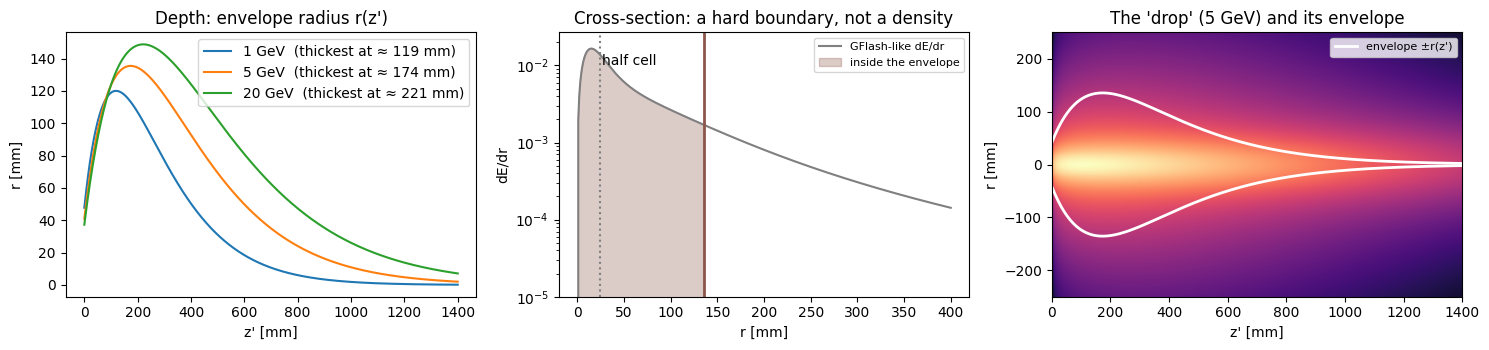

In [1]:
import numpy as np, matplotlib.pyplot as plt

# the same illustrative hadron shower as in the GFlash notebook (01), so the two introductions can be compared panel by panel
LAM = 170.0                                 # illustrative: nuclear interaction length [mm]
Rc, Rt, pc, z0 = 25.0, 110.0, 0.6, -25.0
z = np.linspace(0.1, 1400, 400)


def envelope(z, E):
    """Illustrative envelope: thickest point follows t_max (grows with ln E), the radius is nearly energy independent."""
    zenv = LAM * (0.2 * np.log(E) + 0.7)
    a = 1.0; b = a / (zenv - z0); rmax = 120 * (1 + 0.08 * np.log(E))
    u = np.clip(z - z0, 0, None)
    return rmax * (u / (zenv - z0)) ** a * np.exp(-b * u + a), zenv


fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for E in (1, 5, 20):
    r, zenv = envelope(z, E)
    ax[0].plot(z, r, label=f"{E} GeV  (thickest at ≈ {zenv:.0f} mm)")
ax[0].set(title="Depth: envelope radius r(z')", xlabel="z' [mm]", ylabel="r [mm]"); ax[0].legend()

rr = np.linspace(0, 400, 400)
T = (pc * Rc**2 / (rr**2 + Rc**2)**2 + (1 - pc) * Rt**2 / (rr**2 + Rt**2)**2) / np.pi
dEdr = 2 * np.pi * rr * T
r_env = envelope(np.array([LAM * (0.2 * np.log(5) + 0.7)]), 5)[0][0]
ax[1].semilogy(rr, dEdr, c="grey", label="GFlash-like dE/dr")
ax[1].fill_between(rr, 1e-6, dEdr, where=rr <= r_env, color="tab:brown", alpha=0.3, label="inside the envelope")
ax[1].axvline(r_env, c="tab:brown", lw=2); ax[1].axvline(24, ls=":", c="grey"); ax[1].text(26, 1e-2, "half cell")
ax[1].set_ylim(1e-5, None)
ax[1].set(title="Cross-section: a hard boundary, not a density", xlabel="r [mm]", ylabel="dE/dr"); ax[1].legend(fontsize=8)

Z, R = np.meshgrid(z, np.linspace(-250, 250, 241))
tmax = LAM * (0.2 * np.log(5) + 0.7); bb = 0.5 / LAM; aa = 1 + bb * tmax
rc = Rc * (1 + Z / 800)
rho = Z ** (aa - 1) * np.exp(-bb * Z) * (pc * rc**2 / (R**2 + rc**2)**2 + (1 - pc) * (4 * rc)**2 / (R**2 + (4 * rc)**2)**2)
ax[2].imshow(np.log10(rho + 1e-30), extent=[0, 1400, -250, 250], aspect="auto", origin="lower", cmap="magma",
             vmin=np.log10(rho.max()) - 4)
r5, _ = envelope(z, 5)
ax[2].plot(z, r5, c="white", lw=2); ax[2].plot(z, -r5, c="white", lw=2, label="envelope ±r(z')")
ax[2].set_ylim(-250, 250); ax[2].legend(loc="upper right", fontsize=8)
ax[2].set(title="The 'drop' (5 GeV) and its envelope", xlabel="z' [mm]", ylabel="r [mm]")
plt.tight_layout(); plt.show()

**Same plots as for GFlash (01):** with the same illustrative shower, so they can be compared panel by panel.
- **Left:** GFlash describes the *depth profile* ($dE/dz'$), the envelope the *radius* ($r(z')$). Here too the thickest point moves deeper
  with energy together with the shower maximum, while the radius barely grows.
- **Middle:** GFlash gives a density ($dE/dr$, grey). The envelope instead is a **hard boundary**: whatever is inside the brown line is "in".
- **Right:** the same "drop" as for GFlash, with the envelope outline $\pm r(z')$ drawn on it.

The plot below shows the fluctuations: the envelope is sized not for the average shower but for 98% of the showers.

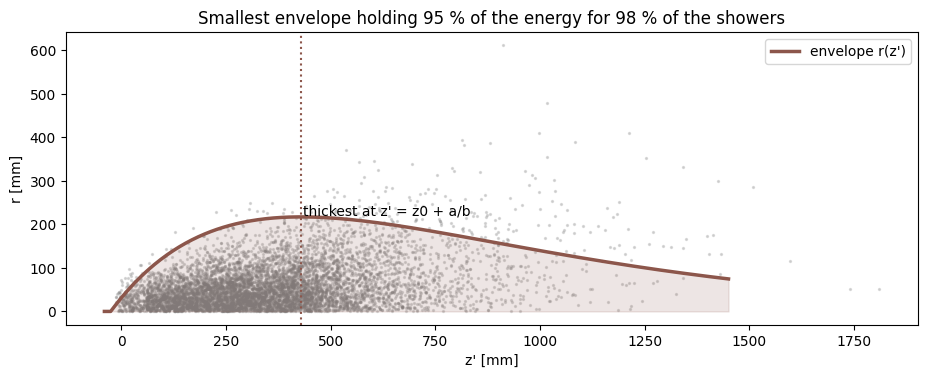

In [2]:
import numpy as np, matplotlib.pyplot as plt
rng = np.random.default_rng(1)
fig, ax = plt.subplots(figsize=(11, 3.8))
for k in range(25):                                         # 25 synthetic showers with fluctuating depth and width
    n = 300; s = rng.exponential(170) + rng.gamma(2 + rng.normal(0, 0.5), 120, n); q = np.abs(rng.normal(0, 30 + 0.12 * s * rng.uniform(0.7, 1.4)))
    ax.scatter(s - 15, q, s=2, alpha=0.25, c="grey")
A, a, b, z0 = 1.3, 1.0, 0.0022, -25
z = np.linspace(-40, 1450, 400); u = np.clip(z - z0, 0, None); r = A * u ** a * np.exp(-b * u)
ax.fill_between(z, 0, r, color="tab:brown", alpha=0.15); ax.plot(z, r, c="tab:brown", lw=2.5, label="envelope r(z')")
ax.axvline(z0 + a / b, ls=":", c="tab:brown"); ax.text(z0 + a / b + 5, r.max() * 1.02, "thickest at z' = z0 + a/b")
ax.set(xlabel="z' [mm]", ylabel="r [mm]", title="Smallest envelope holding 95 % of the energy for 98 % of the showers")
ax.legend(); plt.show()

## 2. Loading data

In [3]:
PARTICLES = ['proton']
DATA_DIR = "../../data/simulations/regression-proton/"          # location of the CSVs
OUT_DIR = "results"        # models and exports go here
%run -i ./00_common.ipynb

/home/user/.venv/lib/python3.10/site-packages/nbformat/__init__.py:96: MissingIDFieldWarning: Cell is missing an id field, this will become a hard error in future nbformat versions. You may want to use `normalize()` on your notebooks before validations (available since nbformat 5.1.4). Previous versions of nbformat are fixing this issue transparently, and will stop doing so in the future.
  validate(nb)


device: cuda | data: ../../data/simulations/regression-proton/ | output: results


In [4]:
DATA = {}
for particle in PARTICLES:
    df, geo, DATA[particle] = load_data(particle)
    print(f"\n===== {particle} =====")
    df.info()
    display(df.describe().T)
    display(df.head())

proton: 99925 events, geometry {'layer': 20.5, 'cell': 48.59999999999991, 'z_back': 4882.15}, split train 69946, val 14987, test 14992

===== proton =====
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54740548 entries, 0 to 54740547
Data columns (total 21 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   event_number                int64  
 1   cellID                      int64  
 2   x                           float64
 3   y                           float64
 4   z                           float64
 5   x_local                     float64
 6   y_local                     float64
 7   z_local                     float64
 8   x_trans                     float64
 9   y_trans                     float64
 10  z_trans                     float64
 11  energy                      float64
 12  earliest_contribution_time  float64
 13  incoming_momentum           float64
 14  incoming_theta              float64
 15  incoming_phi                

,count,mean,std,min,25%,50%,75%,max
event_number,54740548.0,1.061527e+05,7.737650e+04,3.000000e+00,5.248700e+04,1.050650e+05,1.577730e+05,2.119982e+06
cellID,54740548.0,2.078115e+09,1.471819e+09,4.212000e+03,7.136951e+08,1.745523e+09,3.306567e+09,5.063386e+09
x,54740548.0,8.340518e+00,1.308310e+03,-2.596035e+03,-1.032024e+03,3.040900e+01,1.041428e+03,2.601035e+03
y,54740548.0,-3.721223e+00,1.311835e+03,-2.599800e+03,-1.036200e+03,-2.620000e+01,1.036200e+03,2.599800e+03
z,54740548.0,4.087755e+03,2.839532e+02,3.662400e+03,3.867400e+03,4.031400e+03,4.277400e+03,4.871900e+03
x_local,54740548.0,-4.207020e+01,2.241171e+02,-4.896420e+03,-1.444550e+02,-3.088325e+01,6.947679e+01,2.979718e+03
y_local,54740548.0,1.054415e-01,2.235098e+02,-3.319625e+03,-1.091375e+02,0.000000e+00,1.090265e+02,3.238695e+03
z_local,54740548.0,4.406571e+02,3.025983e+02,-2.931879e+03,2.039936e+02,3.921629e+02,6.374536e+02,2.667495e+03
x_trans,54740548.0,6.120635e-02,2.520863e+02,-4.887696e+03,-1.398834e+02,0.000000e+00,1.412087e+02,5.140408e+03
y_trans,54740548.0,3.625353e-03,2.520673e+02,-4.894655e+03,-1.405741e+02,0.000000e+00,1.403782e+02,5.147369e+03


,event_number,cellID,x,y,z,x_local,y_local,z_local,x_trans,y_trans,...,energy,earliest_contribution_time,incoming_momentum,incoming_theta,incoming_phi,incoming_momentum_bin,particle_type,is_secondary,parent_type,daughter_type
0,186640,2823563636,-1387.531982,-2147.199951,4379.899902,-130.723225,-378.459188,761.351211,-463.007620,-103.890706,...,4.238810e-08,1200.353271,17.044954,0.549644,-1.997623,17,neutron,1,neutron,gamma;gamma
1,132450,163584116,132.927994,2551.199951,4277.399902,69.697194,210.840800,750.914462,-152.802091,460.011513,...,6.959773e-08,574.963501,13.259551,0.524659,1.441496,13,neutron,1,neutron,proton;proton
2,1436,2307335028,-830.135010,-175.800003,4359.399902,-226.855893,-0.924198,665.431786,90.170637,18.004689,...,6.916019e-04,14.909340,16.654422,0.197399,-2.954562,16,proton,1,neutron,e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e-;e...
3,118990,608834164,835.135010,-1339.199951,3887.899902,-119.737264,179.827552,193.795084,146.963886,108.548892,...,1.211111e-08,1620.073486,19.433977,0.411175,-1.112347,19,neutron,1,neutron,NaN
4,49113,4412592500,984.348999,1440.199951,4236.399902,-218.178821,-147.723526,531.631196,141.541496,-50.457615,...,2.290001e-05,165.507782,17.042273,0.437355,1.044127,17,neutron,1,neutron,gamma;gamma;gamma


## 3. The model

Three steps:

1. **Deposits:** every hit is split into a few points within the cell (the same detector convolution as for the other models).
2. **Exact $A$:** `required_logA` computes the required $\log A$ for each shower (weighted quantile), and `bin_threshold` takes
   their 98th percentile.
3. **Search:** a coarse grid search over $(a, z_{env}=a/b, z_0)$, then Nelder–Mead refinement. The objective is $\log V$.

### What do we fit to, and what affects the estimate?

This is **not a likelihood fit** but a per-bin volume minimisation, so the data affect it differently than the density models:
- **Features used:** `x_local, y_local, z_local` → $z'$, $r$ and `energy` → $w$ (normalised per event). Every hit is split into $K=8$
  points within the rotated cell (`deposits`, which needs the `incoming_theta`, `incoming_phi` columns and the geometry).
- **Momentum:** not a continuous condition. Data are **split into 1 GeV bins** by `incoming_momentum_bin`, and each bin is fitted separately;
  the bin mean of `incoming_momentum` is only needed for the later $\ln p$ polynomial.
- **Objective:** $\log V$, subject to $F_E=95\%$ of the energy being inside the envelope for $F_{EV}=98\%$ of the showers.
  Hence the envelope is determined by **the fluctuations of individual showers** (the extreme showers), not by the average shape.
- **What else affects it:** the values of $F_E$ and $F_{EV}$, the number of training events per bin (on a small sample 98% is effectively the worst shower),
  the grid-search range and the Nelder–Mead starting point. The same cuts apply (`earliest_contribution_time`, $z'$ and $r$ range).
- There is **no** back-face truncation ($z_b$) and no validation early stopping; the test set is only used to check coverage.

In [5]:
F_E, F_EV = 0.95, 0.98                       # energy fraction inside, for this fraction of the showers


def deposits(sh, K=8, seed=3):
    """Every hit -> K points inside its (rotated) cell, weight w/K."""
    gen = torch.Generator(device=DEVICE).manual_seed(seed)
    b = sh.batch(torch.arange(len(sh), device=DEVICE))
    pts = fold(b, sh.box, K, gen)
    return {"z": pts[..., 2].reshape(-1), "r": torch.sqrt(pts[..., 0] ** 2 + pts[..., 1] ** 2).reshape(-1),
            "w": (b.w[:, None] / K).expand(-1, K).reshape(-1), "ev": b.ev[:, None].expand(-1, K).reshape(-1), "n": len(sh)}


def required_logA(P, a, b, z0, f_e=F_E):
    """Per shower: smallest log A that puts a fraction f_e of its energy inside r = A u^a e^{-bu}."""
    u = P["z"] - z0
    s = torch.full_like(u, float("inf"))                                  # points before z0 can never be inside
    ok = u > 0
    s[ok] = torch.log(P["r"][ok].clamp_min(1e-6)) - a * torch.log(u[ok]) + b * u[ok]
    o = torch.argsort(s, stable=True)
    o = o[torch.argsort(P["ev"][o], stable=True)]                        # sorted by shower, then by s
    s, w, e = s[o], P["w"][o].double(), P["ev"][o]
    c = torch.cumsum(w, 0)
    cnt = torch.bincount(e, minlength=P["n"])
    start = torch.cumsum(cnt, 0) - cnt
    before = c[start] - w[start]
    idx = torch.minimum(torch.searchsorted(c, before + f_e * (c[start + cnt - 1] - before)), start + cnt - 1)
    return s[idx]


def bin_threshold(P, a, b, z0, f_ev=F_EV):
    return float(np.quantile(required_logA(P, a, b, z0).cpu().numpy(), f_ev, method="higher"))


def log_volume(logA, a, b):
    return math.log(math.pi) + 2 * logA + math.lgamma(2 * a + 1) - (2 * a + 1) * math.log(2 * b)


def fit_bin(P):
    def objective(x):
        a, zenv, z0 = math.exp(x[0]), math.exp(x[1]), x[2]
        if not (0.05 < a < 10 and 3 < zenv < 1500 and -200 < z0 < 50):
            return 1e6
        logA = bin_threshold(P, a, a / zenv, z0)
        return log_volume(logA, a, a / zenv) if np.isfinite(logA) else 1e6
    grid = [(la, lz, z0) for la in np.linspace(math.log(0.1), math.log(6), 12)
            for lz in np.linspace(math.log(5), math.log(1200), 12) for z0 in (-60, -30, -10)]
    x0 = min(grid, key=objective)
    x = minimize(objective, x0, method="Nelder-Mead", options={"maxiter": 300}).x
    a, zenv, z0 = math.exp(x[0]), math.exp(x[1]), x[2]
    logA = bin_threshold(P, a, a / zenv, z0)
    return {"a": a, "b": a / zenv, "z_env": zenv, "z0": z0, "A": math.exp(logA),
            "r_max": math.exp(logA) * zenv ** a * math.exp(-a), "V_L": math.exp(log_volume(logA, a, a / zenv)) / 1e6}


def coverage(P, e):
    """Fraction of showers that keep >= F_E of their energy inside envelope e."""
    return float((required_logA(P, e["a"], e["b"], e["z0"]) <= math.log(e["A"]) + 1e-9).float().mean())

## 4. Per-bin fit

There are 20 bins, each a 1 GeV momentum range. The result is saved per bin to `results/proton/envelope.pt`, so after an interruption
it resumes from there. The **test coverage** shows on unseen showers whether the 98% target is actually met. On a small sample this is noisy:
in the 1000-event sample there are only ~35 training showers per bin, where 98% effectively means the worst shower.

In [6]:
data = DATA["proton"]
path = f"{OUT_DIR}/proton/envelope.pt"
ENV = torch.load(path, weights_only=False) if os.path.exists(path) else {}
for b in range(20):
    if b in ENV:
        continue
    tr = (data["train"].ev["bin"] == b).nonzero().squeeze(1)
    te = (data["test"].ev["bin"] == b).nonzero().squeeze(1)
    if len(tr) == 0:
        continue
    P = deposits(data["train"].subset(tr))
    e = fit_bin(P)
    e["p_mean"], e["n_train"] = float(data["train"].ev["p"][tr].mean()), len(tr)
    e["cov_train"] = coverage(P, e)
    e["cov_test"] = coverage(deposits(data["test"].subset(te)), e) if len(te) else float("nan")
    ENV[b] = e
    torch.save(ENV, path)
    print(f"bin {b:2d}–{b + 1:2d} GeV: V = {e['V_L']:7.2f} L, a = {e['a']:.2f}, z_env = {e['z_env']:6.1f} mm, "
          f"r_max = {e['r_max']:6.1f} mm, coverage train/test = {e['cov_train']:.2f}/{e['cov_test']:.2f}")

## 5. Energy dependence (the counterpart of "distillation")

A simple $\ln p$ polynomial is fitted to the per-bin $a$, $z_{env}$, $z_0$ and $A$ values; the degree (0–2) is chosen by BIC.
This gives the closed-form energy dependence of the envelope.

This second fit is no longer to the data but to the per-bin parameters (the $a$, $z_{env}$, $z_0$, $A$ values), unweighted, as a function of the bin-mean $\ln p$. A poorly fitting bin (few events, extreme shower) therefore directly distorts the polynomial.

In [7]:
tab = pd.DataFrame(ENV).T.sort_index()
tab["z_thick"] = tab.z0 + tab.z_env                  # z_env = a/b is measured from z0
x = np.log(tab.p_mean.values)
SMOOTH = {}
for name, y in {"ln a": np.log(tab.a.values), "ln z_env": np.log(tab.z_env.values), "z0": tab.z0.values, "ln A": np.log(tab.A.values)}.items():
    best = None
    for d in range(3):
        c = np.polynomial.polynomial.polyfit(x, y, d)
        rss = np.sum((np.polynomial.polynomial.polyval(x, c) - y) ** 2) + 1e-12
        bic = len(x) * np.log(rss / len(x)) + (d + 1) * np.log(len(x))
        if best is None or bic < best[0]:
            best = (bic, d, c)
    SMOOTH[name] = best[2]
    print(f"{name:9s} = " + " ".join(f"{v:+.4f}·L^{k}" for k, v in enumerate(best[2])) + f"   (degree {best[1]}, L = ln p)")
display(tab[["p_mean", "n_train", "a", "z_env", "z_thick", "z0", "A", "r_max", "V_L", "cov_train", "cov_test"]].round(3))

ln a      = -0.2709·L^0 -0.1941·L^1   (degree 1, L = ln p)
ln z_env  = +5.6149·L^0 +0.6917·L^1 -0.2107·L^2   (degree 2, L = ln p)
z0        = -114.3942·L^0   (degree 0, L = ln p)
ln A      = +3.8001·L^0   (degree 0, L = ln p)


,p_mean,n_train,a,z_env,z_thick,z0,A,r_max,V_L,cov_train,cov_test
0,0.807,3488.0,0.648,191.097,116.718,-74.379,42.989,677.274,645.720,0.98,0.980
1,1.504,3492.0,0.627,394.181,249.272,-144.909,33.438,756.239,1692.674,0.98,0.981
2,2.497,3494.0,0.796,552.499,352.503,-199.995,10.678,735.158,1962.160,0.98,0.975
3,3.503,3494.0,0.816,523.398,375.178,-148.220,10.960,802.978,2187.499,0.98,0.969
4,4.500,3499.0,0.642,546.244,357.922,-188.322,25.088,754.909,2305.933,0.98,0.981
5,5.507,3498.0,0.819,555.754,355.832,-199.922,9.740,761.224,2083.335,0.98,0.976
6,6.500,3498.0,0.502,406.947,296.362,-110.585,61.719,762.445,2015.770,0.98,0.960
7,7.499,3499.0,0.715,535.479,402.913,-132.565,16.918,740.173,2045.767,0.98,0.977
8,8.496,3498.0,0.348,360.993,282.590,-78.403,137.018,752.241,2159.474,0.98,0.973
9,9.502,3498.0,0.446,391.910,330.149,-61.761,90.293,828.979,2457.874,0.98,0.985


## 6. Results

**What to look for:**
- **Volume:** should be a few litres in typical bins. A sudden large value in a bin is caused by a shower with extreme fluctuation;
  this is expected on a small sample.
- **Test coverage:** should be around 0.98 (strongly scattered on a small sample).
- **Parameters:** the thickest point of the envelope ($z_{env}$) should grow roughly with $\ln p$, like the shower maximum.
- **3D:** the envelope is a drop-shaped body; the points are the deposits.

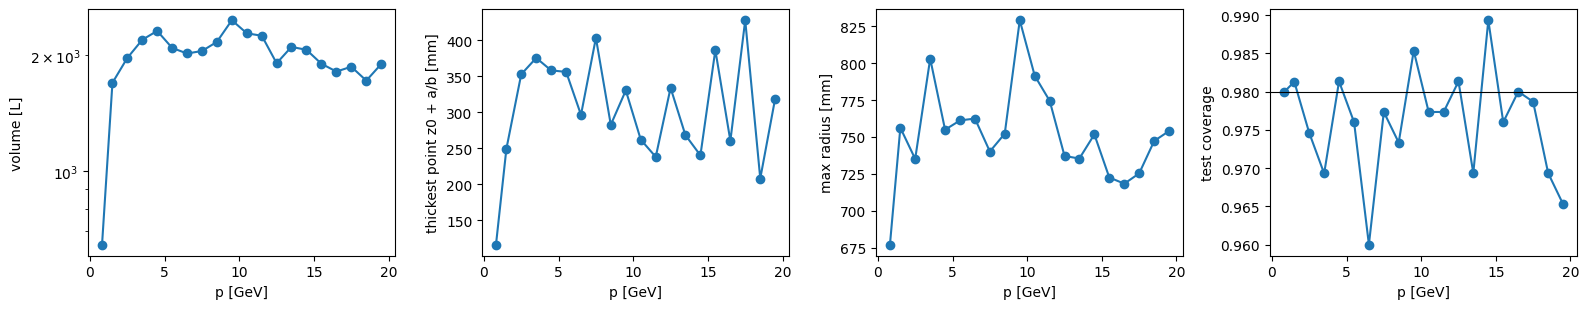

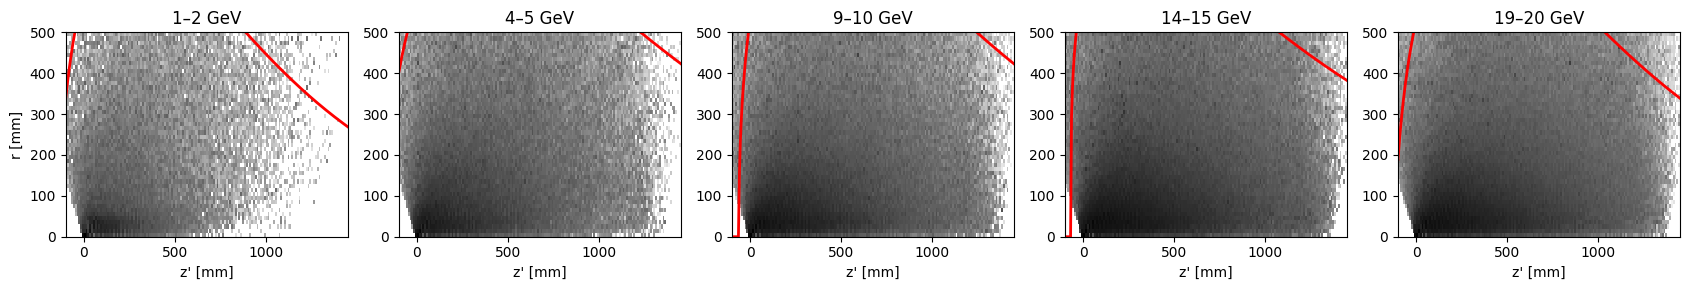

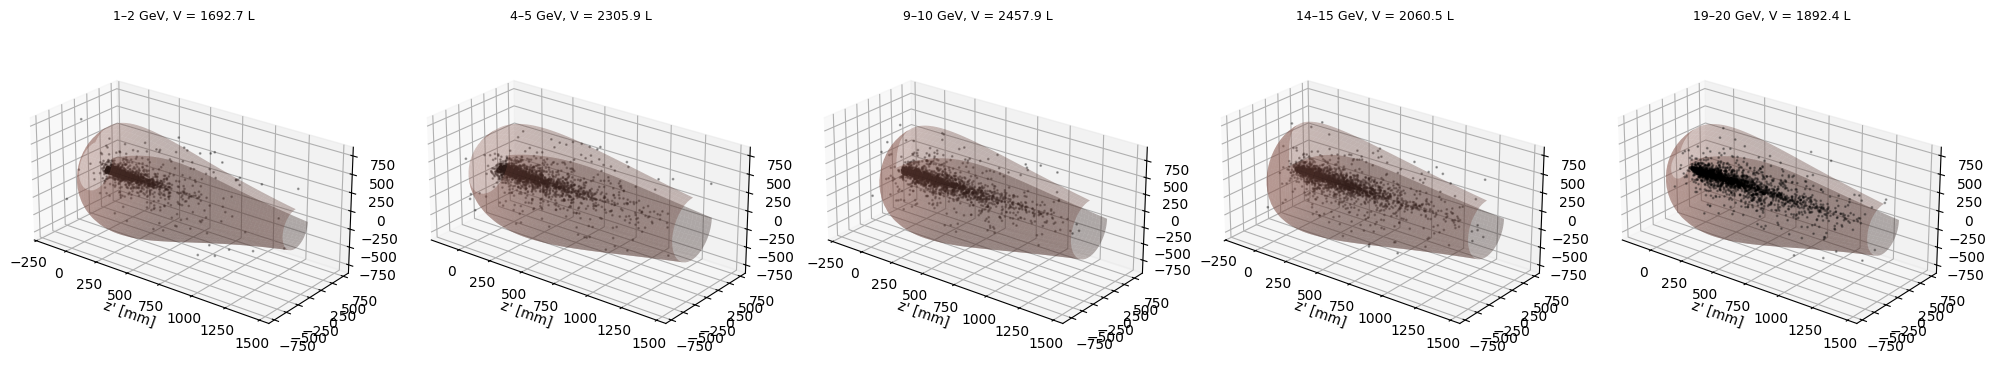

envelope saved for the summary notebook


In [8]:
p = tab.p_mean.values
fig, ax = plt.subplots(1, 4, figsize=(16, 3.2))
for a_, (col, lab) in zip(ax, [("V_L", "volume [L]"), ("z_thick", "thickest point z0 + a/b [mm]"), ("r_max", "max radius [mm]"), ("cov_test", "test coverage")]):
    a_.plot(p, tab[col].values, "o-"); a_.set(xlabel="p [GeV]", ylabel=lab)
ax[0].set_yscale("log"); ax[3].axhline(F_EV, c="k", lw=0.8)
plt.tight_layout(); plt.show()

hits = data["train"].hits()
fig, axes = plt.subplots(1, len(SHOW_BINS), figsize=(3.4 * len(SHOW_BINS), 3))
zz = np.linspace(-100, 1450, 300)
for ax_, b in zip(axes, SHOW_BINS):
    m = (hits.p >= b) & (hits.p < b + 1)
    ax_.hist2d(hits.z[m], hits.r[m], bins=[np.linspace(-100, 1450, 156), np.linspace(0, 500, 51)], weights=hits.w[m],
               norm=matplotlib.colors.LogNorm(), cmap="Greys")
    if b in ENV:
        e = ENV[b]; u = np.clip(zz - e["z0"], 0, None)
        ax_.plot(zz, e["A"] * u ** e["a"] * np.exp(-e["b"] * u), "r-", lw=2)
    ax_.set_title(f"{b}–{b + 1} GeV"); ax_.set_xlabel("z' [mm]")
axes[0].set_ylabel("r [mm]"); plt.tight_layout(); plt.show()

fig = plt.figure(figsize=(4 * len(SHOW_BINS), 3.8))
for j, b in enumerate([b for b in SHOW_BINS if b in ENV]):
    ax_ = fig.add_subplot(1, len(SHOW_BINS), j + 1, projection="3d")
    e = ENV[b]; u = np.clip(zz - e["z0"], 0, None)
    ax_.plot_surface(*revolve(zz, e["A"] * u ** e["a"] * np.exp(-e["b"] * u)), color="tab:brown", alpha=0.35, linewidth=0)
    m = np.where((hits.p >= b) & (hits.p < b + 1))[0]
    sel = np.random.default_rng(0).choice(m, min(2000, len(m)), p=hits.w.values[m] / hits.w.values[m].sum())
    ph = np.random.default_rng(1).uniform(0, 2 * np.pi, len(sel))
    ax_.scatter(hits.z.values[sel], hits.r.values[sel] * np.cos(ph), hits.r.values[sel] * np.sin(ph), s=1, c="k", alpha=0.3)
    ax_.set_title(f"{b}–{b + 1} GeV, V = {e['V_L']:.1f} L", fontsize=9); ax_.set_xlabel("z' [mm]")
    ax_.set_box_aspect((2.2, 1, 1)); ax_.view_init(elev=24, azim=-52)
plt.tight_layout(); plt.show()
torch.save({"bins": ENV, "smooth": {k: v.tolist() for k, v in SMOOTH.items()}, "f_E": F_E, "f_ev": F_EV},
           f"{OUT_DIR}/proton/envelope_export.pt")
print("envelope saved for the summary notebook")

### 2D map with $(z', r)$ axes, in the same form as the GFlash `shape_map` plot

The same view as for the GFlash results: $z'$ horizontal, $r$ mirrored ($\pm r$, mm), $\log_{10}$ density, 5-decade colour scale,
$p = 1, 5, 10, 18$ GeV.
- **Background:** mean energy density of the training data in the given 1 GeV bin, on the same $(z', r)$ grid as the model maps.
  This is the distribution of cell centres, not deconvolved, so it is coarser in $r$ than the GFlash "true shape".
- **White line:** the envelope fitted in the bin. **Cyan dashed:** the smoothed ($\ln p$ polynomial) envelope at the bin mean momentum.
- **Green dotted** (if a GFlash export exists): radius of the GFlash region containing 95% of the energy, $r_{95}(z')$. This is for the **average** shower,
  so it is expected to stay inside the envelope.

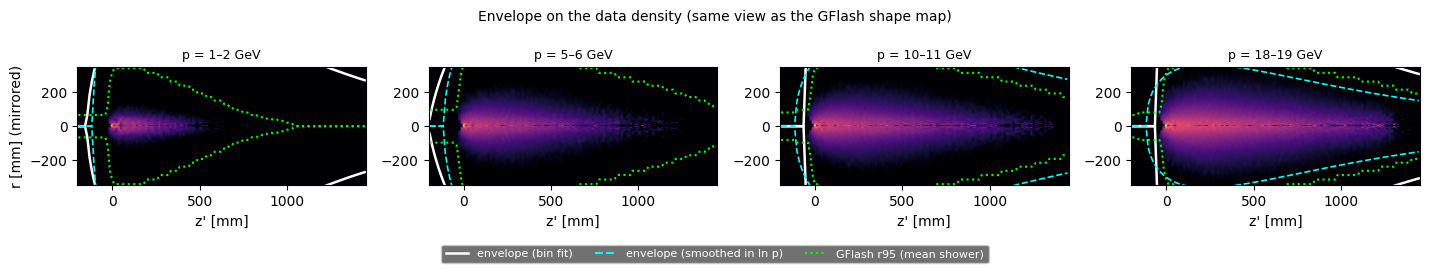

In [9]:
def envelope_r(z, e):
    u = np.clip(z - e["z0"], 0, None)
    return e["A"] * u ** e["a"] * np.exp(-e["b"] * u)


def smooth_envelope(p):
    L = np.log(p)
    v = {k: np.polynomial.polynomial.polyval(L, c) for k, c in SMOOTH.items()}
    a, zenv = np.exp(v["ln a"]), np.exp(v["ln z_env"])
    return {"a": a, "b": a / zenv, "z0": v["z0"], "A": np.exp(v["ln A"])}


def envelope_map(sh, p_values=(1, 5, 10, 18), r_show=350, title=""):
    """Same layout as shape_map: data density in the p bin (log10, mirrored in r) + envelope outlines."""
    zc, rc = ZC.cpu().numpy(), RC.cpu().numpy()
    vol = np.exp(LOG_VOL.cpu().numpy())
    h = sh.hits()
    gf_path = f"{OUT_DIR}/proton/export_gflash.pt"
    gf = TableModel(torch.load(gf_path, weights_only=False)) if os.path.exists(gf_path) else None
    rs = np.linspace(-r_show, r_show, 121)
    fig, axes = plt.subplots(1, len(p_values), figsize=(3.6 * len(p_values), 2.6))
    for ax, p in zip(axes, p_values):
        b = int(p)
        m = (h.p >= b) & (h.p < b + 1)
        H, _, _ = np.histogram2d(h.z[m], h.r[m], bins=[Z_EDGES.cpu().numpy(), R_EDGES.cpu().numpy()], weights=h.w[m])
        d = H / max(h.ev[m].nunique(), 1) / vol
        img = np.log10(np.clip(np.stack([np.interp(np.abs(rs), rc, row) for row in d], 1), 1e-14, None))
        ax.imshow(img, origin="lower", aspect="auto", extent=[Z_MIN, Z_MAX, -r_show, r_show], cmap="magma",
                  vmin=img.max() - 5, vmax=img.max())
        if b in ENV:
            r = envelope_r(zc, ENV[b])
            ax.plot(zc, r, "w-", lw=1.8); ax.plot(zc, -r, "w-", lw=1.8)
            rs_ = envelope_r(zc, smooth_envelope(ENV[b]["p_mean"]))
            ax.plot(zc, rs_, c="cyan", ls="--", lw=1.2); ax.plot(zc, -rs_, c="cyan", ls="--", lw=1.2)
        if gf is not None:
            with torch.no_grad():
                P = gf(torch.log(torch.tensor([b + 0.5], device=DEVICE))).exp()[0].cpu().numpy()
            r95 = iso_radius(P, 0.95)
            ax.plot(zc, r95, c="lime", ls=":", lw=1.5); ax.plot(zc, -r95, c="lime", ls=":", lw=1.5)
        ax.set_ylim(-r_show, r_show)
        ax.set_title(f"p = {b}–{b + 1} GeV", fontsize=9)
        ax.set_xlabel("z' [mm]")
    axes[0].set_ylabel("r [mm] (mirrored)")
    handles = [plt.Line2D([], [], c="w", lw=1.8, label="envelope (bin fit)"),
               plt.Line2D([], [], c="cyan", ls="--", label="envelope (smoothed in ln p)")]
    if gf is not None:
        handles.append(plt.Line2D([], [], c="lime", ls=":", label="GFlash r95 (mean shower)"))
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=8, facecolor="0.3", labelcolor="w")
    fig.suptitle(title, fontsize=10)
    fig.tight_layout(rect=(0, 0.08, 1, 1))
    plt.show()


envelope_map(data["train"], title="Envelope on the data density (same view as the GFlash shape map)")